# Evaluation: Avg VTAT as a Label Proxy, Tuning, and Final Model

In this notebook we show that Avg VTAT encodes the outcome (it acts as a proxy for the label) in our baseline model, remove it, tune three models on the remaining features, and evaluate the final model on the test set.

**Scope of the VTAT claim:** the evidence below shows that Avg VTAT's range depends on the outcome (values above 15 appear only on cancelled rides). It does not show *when* the value was recorded, so we do not claim it was logged after the cancellation. Either way it cannot be used as a legitimate predictor.

In [1]:
import sys
import importlib
sys.path.insert(0, '..')
import src.preproc
importlib.reload(src.preproc)
from src.preproc import prepare_data, create_preprocessor

import pandas as pd
import numpy as np
import matplotlib.pyplot
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score

In [2]:
# Load the dataset and keep the 7 baseline features, including Avg VTAT
df = pd.read_csv('../data/uberData.csv')

features_vtat = ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Hour', 'DayOfWeek', 'Month', 'Avg VTAT']
features_base = ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Hour', 'DayOfWeek', 'Month']

X, y = prepare_data(df, features=features_vtat)

# Add the engineered features (these only use each row's own booking time and locations)
# Sine and cosine transformations for cyclical features (Make earlier hours and months closer to later hours and months)
X['Hour_sin'] = np.sin(2 * np.pi * X['Hour'] / 24)
X['Hour_cos'] = np.cos(2 * np.pi * X['Hour'] / 24)
X['Month_sin'] = np.sin(2 * np.pi * (X['Month'] - 1) / 12)
X['Month_cos'] = np.cos(2 * np.pi * (X['Month'] - 1) / 12)
X['IsWeekend'] = (X['DayOfWeek'] >= 5).astype(int)
X['Route'] = X['Pickup Location'] + ' -> ' + X['Drop Location']

print('Dimensions of X:', X.shape)
print('Cancellation rate:', round(y.mean(), 4))

Dimensions of X: (103500, 13)
Cancellation rate: 0.1014


In [3]:
# Split the dataset into 70% training, 15% validation and 15% testing sets (same split as notebook 03)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

# Print the dimensions of the training, validation and testing sets
print('Dimensions of training set X_train:', X_train.shape)
print('Dimensions of validation set X_val:', X_val.shape)
print('Dimensions of testing set X_test:', X_test.shape)

Dimensions of training set X_train: (72450, 13)
Dimensions of validation set X_val: (15525, 13)
Dimensions of testing set X_test: (15525, 13)


## Step 1: Showing that Avg VTAT encodes the outcome

In [4]:
# Construct the baseline random forest pipeline from notebook 03 (with Avg VTAT)
rf_vtat = Pipeline([
    ('preprocessor', create_preprocessor(features_vtat)),
    ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1))
])

# Fit the pipeline to the training data and predict on the validation set
rf_vtat.fit(X_train[features_vtat], y_train)
rf_vtat_probs = rf_vtat.predict_proba(X_val[features_vtat])[:, 1]
rf_vtat_pred = (rf_vtat_probs >= 0.5).astype(int)

# Report the average precision, precision and recall of the baseline
print('Baseline random forest (with Avg VTAT) on the validation set:')
print('Average precision:', round(average_precision_score(y_val, rf_vtat_probs), 4))
print('Precision:', round(precision_score(y_val, rf_vtat_pred), 3))
print('Recall:', round(recall_score(y_val, rf_vtat_pred), 3))

Baseline random forest (with Avg VTAT) on the validation set:
Average precision: 0.4766
Precision: 0.947
Recall: 0.331


Avg VTAT by group:
             count   mean   std  min   25%   50%   75%   max
caught       522.0  17.50  1.55  8.2  16.3  17.5  18.7  20.0
completed  13950.0   8.52  3.73  2.0   5.3   8.5  11.8  15.0
missed      1053.0   9.90  2.91  5.0   7.4   9.7  12.6  15.0 

caught: share of VTAT values never seen in completed rides = 0.994
missed: share of VTAT values never seen in completed rides = 0.000


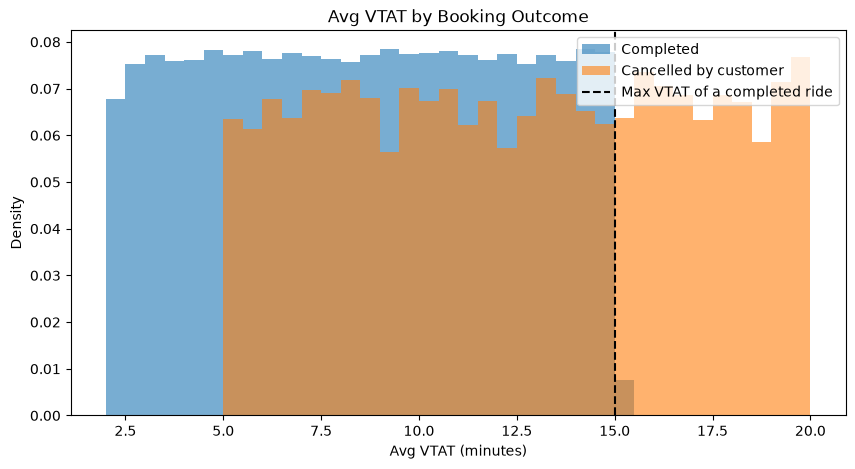

In [5]:
# Split the validation rows into cancellations the model caught, cancellations it missed, and completed rides
groups = pd.Series('completed', index=X_val.index)
groups[(y_val == 1) & (rf_vtat_probs >= 0.5)] = 'caught'
groups[(y_val == 1) & (rf_vtat_probs < 0.5)] = 'missed'

# Print the summary statistics of Avg VTAT for each group
print('Avg VTAT by group:')
print(X_val.groupby(groups)['Avg VTAT'].describe().round(2), '\n')

# Check how many of the VTAT values in each group never appear in a completed ride
completed_values = set(X_train.loc[y_train == 0, 'Avg VTAT'].round(1))
for group in ['caught', 'missed']:
    values = X_val.loc[groups == group, 'Avg VTAT'].round(1)
    print(f'{group}: share of VTAT values never seen in completed rides = {(~values.isin(completed_values)).mean():.3f}')

# Plot the distribution of Avg VTAT for completed and cancelled rides
bins = np.arange(2, 20.5, 0.5)
matplotlib.pyplot.figure(figsize=(10, 5))
matplotlib.pyplot.hist(X.loc[y == 0, 'Avg VTAT'], bins=bins, density=True, alpha=0.6, label='Completed')
matplotlib.pyplot.hist(X.loc[y == 1, 'Avg VTAT'], bins=bins, density=True, alpha=0.6, label='Cancelled by customer')
matplotlib.pyplot.axvline(15, color='black', linestyle='--', label='Max VTAT of a completed ride')
matplotlib.pyplot.xlabel('Avg VTAT (minutes)')
matplotlib.pyplot.ylabel('Density')
matplotlib.pyplot.title('Avg VTAT by Booking Outcome')
matplotlib.pyplot.legend()
matplotlib.pyplot.show()

In [6]:
# Count completed and cancelled rides in each Avg VTAT range
vtat_ranges = pd.cut(X['Avg VTAT'], [0, 5, 15, 25], labels=['< 5', '5 - 15', '> 15'])
print('Avg VTAT range vs. booking outcome:')
print(pd.crosstab(vtat_ranges, y.map({0: 'Completed', 1: 'Cancelled'}), margins=True), '\n')

# Compare the random forest to a single rule: predict cancelled if Avg VTAT is above 15
rule_pred = (X_val['Avg VTAT'] > 15).astype(int)

results = []
for name, pred in [('Random forest (threshold 0.5)', rf_vtat_pred), ('Rule: VTAT > 15', rule_pred)]:
    results.append({
        'model': name,
        'precision': precision_score(y_val, pred),
        'recall': recall_score(y_val, pred),
        'f1': f1_score(y_val, pred)
    })

rule_df = pd.DataFrame(results)
print(rule_df.round(3))

Avg VTAT range vs. booking outcome:
target    Cancelled  Completed     All
Avg VTAT                              
< 5              33      21670   21703
5 - 15         6946      71330   78276
> 15           3521          0    3521
All           10500      93000  103500 

                           model  precision  recall     f1
0  Random forest (threshold 0.5)      0.947   0.331  0.491
1                Rule: VTAT > 15      1.000   0.330  0.496


                 model      features  validation_AP
0  Logistic Regression     with VTAT         0.4397
1  Logistic Regression  without VTAT         0.1034
2        Random Forest     with VTAT         0.4766
3        Random Forest  without VTAT         0.1024 

Dummy (base rate) average precision: 0.1014


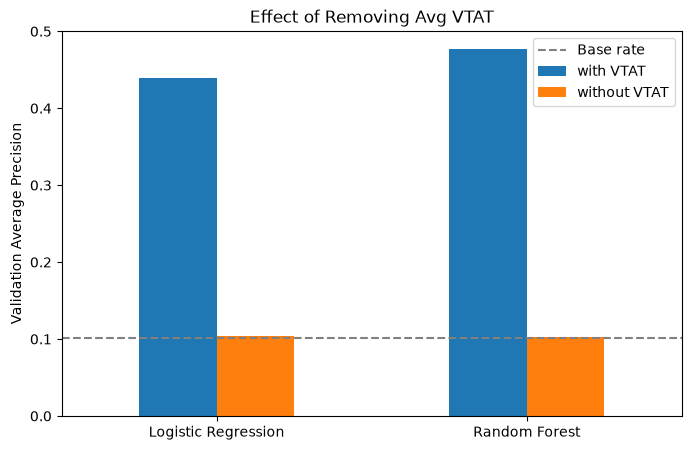

In [7]:
from sklearn.dummy import DummyClassifier

# Train logistic regression and random forest with and without Avg VTAT and compare validation average precision
results = []
for model_name in ['Logistic Regression', 'Random Forest']:
    for feature_set_name, feature_set in [('with VTAT', features_vtat), ('without VTAT', features_base)]:
        if model_name == 'Logistic Regression':
            classifier = LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42)
        else:
            classifier = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)

        pipeline = Pipeline([
            ('preprocessor', create_preprocessor(feature_set)),
            ('classifier', classifier)
        ])
        pipeline.fit(X_train[feature_set], y_train)
        val_probs = pipeline.predict_proba(X_val[feature_set])[:, 1]

        results.append({
            'model': model_name,
            'features': feature_set_name,
            'validation_AP': average_precision_score(y_val, val_probs)
        })

ablation_df = pd.DataFrame(results)
print(ablation_df.round(4), '\n')

# A dummy model that always predicts the base rate, for comparison
dummy = DummyClassifier(strategy='prior')
dummy.fit(X_train[features_base], y_train)
dummy_ap = average_precision_score(y_val, dummy.predict_proba(X_val[features_base])[:, 1])
print('Dummy (base rate) average precision:', round(dummy_ap, 4))

# Plot validation average precision with and without Avg VTAT
plot_df = ablation_df.pivot(index='model', columns='features', values='validation_AP')[['with VTAT', 'without VTAT']]
plot_df.plot(kind='bar', figsize=(8, 5))
matplotlib.pyplot.axhline(dummy_ap, color='gray', linestyle='--', label='Base rate')
matplotlib.pyplot.ylabel('Validation Average Precision')
matplotlib.pyplot.xlabel('')
matplotlib.pyplot.title('Effect of Removing Avg VTAT')
matplotlib.pyplot.xticks(rotation=0)
matplotlib.pyplot.legend()
matplotlib.pyplot.show()

## Step 2: Preprocessing without Avg VTAT

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

numeric_features = ['Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'IsWeekend']
onehot_features = ['Vehicle Type', 'DayOfWeek']
target_features = ['Pickup Location', 'Drop Location', 'Route']
final_features = numeric_features + onehot_features + target_features

# Construct a ColumnTransformer that scales the numeric features, one-hot encodes vehicle type and day,
# and target encodes the pickup, drop and route features
preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), numeric_features),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), onehot_features),
        ('target', TargetEncoder(target_type='binary', random_state=42), target_features)
    ]
)

# Combine the training and validation sets for cross-validation; the test set is not used until the end
X_dev = pd.concat([X_train, X_val])[final_features]
y_dev = pd.concat([y_train, y_val])
X_test = X_test[final_features]

print('Dimensions of X_dev:', X_dev.shape)
print('Dimensions of X_test:', X_test.shape)
print('Number of distinct routes:', X_dev['Route'].nunique())

Dimensions of X_dev: (87975, 10)
Dimensions of X_test: (15525, 10)
Number of distinct routes: 28944


## Step 3: Hyperparameter tuning

Tuning Logistic Regression ...


Tuning Random Forest ...


Tuning Gradient Boosting ...



Tuning results:
                 model  mean_validation_AP  std_validation_AP  \
2    Gradient Boosting              0.1028             0.0029   
0  Logistic Regression              0.1026             0.0017   
1        Random Forest              0.1025             0.0020   

                                         best_params  
2  {'min_samples_leaf': 20, 'max_iter': 100, 'max...  
0                                         {'C': 1.0}  
1  {'min_samples_leaf': 1, 'max_features': 'sqrt'...  

Base rate (dummy average precision): 0.1014


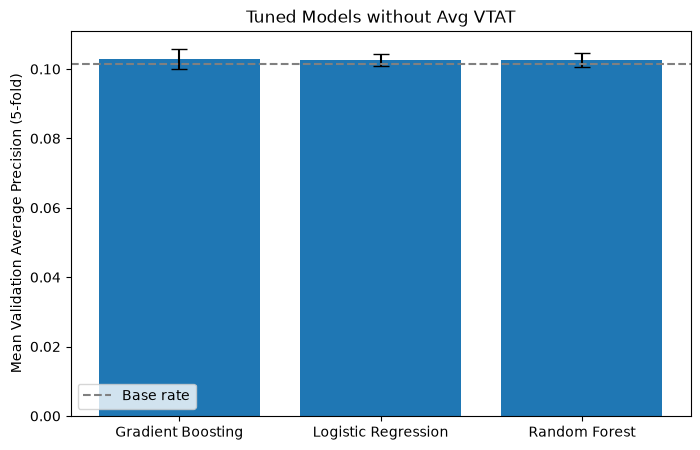

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.base import clone

# Create a stratified k-fold with n_splits=5, shuffle=True, and random_state=42
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hyperparameter dictionaries for each model
models = [
    ('Logistic Regression',
     LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42),
     {'classifier__C': [0.01, 0.1, 1.0, 10.0]},
     4),
    ('Random Forest',
     RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
     {'classifier__max_depth': [6, 10, 20, None],
      'classifier__min_samples_leaf': [1, 5, 20, 50],
      'classifier__max_features': ['sqrt', 0.5]},
     12),
    ('Gradient Boosting',
     HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
     {'classifier__learning_rate': [0.05, 0.1],
      'classifier__max_depth': [3, 6, None],
      'classifier__max_iter': [100, 200, 400],
      'classifier__min_samples_leaf': [20, 100]},
     12)
]

results = []
searches = {}

for name, classifier, hyperparameter_dict, n_iter in models:
    # Construct a pipeline containing the preprocessor and the classifier
    pipeline = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', classifier)
    ])

    # Configure RandomizedSearchCV using average precision as the score
    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=hyperparameter_dict,
        n_iter=n_iter,
        cv=skf,
        scoring='average_precision',
        random_state=42,
        n_jobs=-1
    )

    print('Tuning', name, '...')
    random_search.fit(X_dev, y_dev)
    searches[name] = random_search

    # Identify the configuration that produced the best mean validation average precision
    best_index = random_search.cv_results_['mean_test_score'].argmax()
    results.append({
        'model': name,
        'mean_validation_AP': random_search.cv_results_['mean_test_score'][best_index],
        'std_validation_AP': random_search.cv_results_['std_test_score'][best_index],
        'best_params': {key.replace('classifier__', ''): value for key, value in random_search.cv_results_['params'][best_index].items()}
    })

results_df = pd.DataFrame(results).sort_values('mean_validation_AP', ascending=False)
base_rate = y_dev.mean()

print('\nTuning results:')
print(results_df.round(4))
print('\nBase rate (dummy average precision):', round(base_rate, 4))

# Plot the mean validation average precision for each tuned model
matplotlib.pyplot.figure(figsize=(8, 5))
matplotlib.pyplot.bar(results_df['model'], results_df['mean_validation_AP'], yerr=results_df['std_validation_AP'], capsize=6)
matplotlib.pyplot.axhline(base_rate, color='gray', linestyle='--', label='Base rate')
matplotlib.pyplot.ylabel('Mean Validation Average Precision (5-fold)')
matplotlib.pyplot.title('Tuned Models without Avg VTAT')
matplotlib.pyplot.legend()
matplotlib.pyplot.show()

## Step 4: Final model and test set evaluation

Note on the test set: notebook 03 already evaluated the with-VTAT baseline on this same test split. Every decision about the no-VTAT final model (features, model, hyperparameters, threshold) is made with cross-validation on the development set only, so the test set is touched once *for the final model*.

In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

# Choose the simplest model whose score is within one standard deviation of the best model
complexity = {'Logistic Regression': 0, 'Random Forest': 1, 'Gradient Boosting': 2}
best_row = results_df.iloc[0]
close_models = results_df[results_df['mean_validation_AP'] >= best_row['mean_validation_AP'] - best_row['std_validation_AP']]
final_name = min(close_models['model'], key=complexity.get)
final_pipeline = searches[final_name].best_estimator_
print('Final model:', final_name)

# Choose the threshold that maximizes F1 on the cross-validated predictions of the development set
oof_probs = cross_val_predict(final_pipeline, X_dev, y_dev, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_dev, oof_probs)
f1_scores = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
best_threshold_index = np.argmax(f1_scores)
threshold = thresholds[best_threshold_index]

print(f'Threshold: {threshold:.3f}')
print(f'Precision: {precision[best_threshold_index]:.3f}, Recall: {recall[best_threshold_index]:.3f}, F1: {f1_scores[best_threshold_index]:.3f}')

Final model: Logistic Regression


Threshold: 0.440
Precision: 0.101, Recall: 1.000, F1: 0.184


**Reading this result.** No threshold can beat the base rate here, because none of the tuned models has signal once Avg VTAT is removed (all cross-validated average precision scores are within about one standard deviation of the base rate). Maximizing F1 on noise lands on the degenerate threshold that flags every ride as cancelled: precision equal to the base rate and recall of 1.0. The final model below is therefore a documented null result, not a usable classifier.

Real 5-fold CV average precision:     0.1026
Shuffled-label average precision:     mean 0.1019, std 0.0013
Permutation p-value (100 shuffles):   0.327
Not significant: no evidence the model beats chance (this cannot prove signal is absent, only that none is detected).


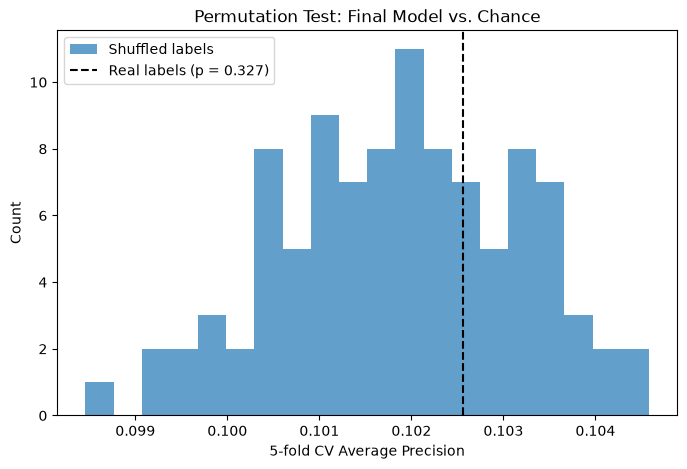

In [11]:
from sklearn.model_selection import permutation_test_score

# Formal check that the final pipeline is no better than chance: shuffle the labels 100 times,
# rerun the same 5-fold CV each time, and count how often shuffled labels score as well as the real ones.
# Only the development set is used; the test set is untouched.
perm_score, perm_scores, perm_p_value = permutation_test_score(
    clone(final_pipeline), X_dev, y_dev,
    scoring='average_precision', cv=skf,
    n_permutations=100, random_state=42, n_jobs=-1
)

print(f'Real 5-fold CV average precision:     {perm_score:.4f}')
print(f'Shuffled-label average precision:     mean {perm_scores.mean():.4f}, std {perm_scores.std():.4f}')
print(f'Permutation p-value (100 shuffles):   {perm_p_value:.3f}')
if perm_p_value > 0.05:
    print('Not significant: no evidence the model beats chance (this cannot prove signal is absent, only that none is detected).')
else:
    print('Significant at 0.05: the model beats chance, even if the effect is small.')

matplotlib.pyplot.figure(figsize=(8, 5))
matplotlib.pyplot.hist(perm_scores, bins=20, alpha=0.7, label='Shuffled labels')
matplotlib.pyplot.axvline(perm_score, color='black', linestyle='--', label=f'Real labels (p = {perm_p_value:.3f})')
matplotlib.pyplot.xlabel('5-fold CV Average Precision')
matplotlib.pyplot.ylabel('Count')
matplotlib.pyplot.title('Permutation Test: Final Model vs. Chance')
matplotlib.pyplot.legend()
matplotlib.pyplot.show()

Final test results for Logistic Regression
              precision    recall  f1-score   support

   Completed       0.00      0.00      0.00     13950
   Cancelled       0.10      1.00      0.18      1575

    accuracy                           0.10     15525
   macro avg       0.05      0.50      0.09     15525
weighted avg       0.01      0.10      0.02     15525

Test average precision: 0.0986
Base rate: 0.1014


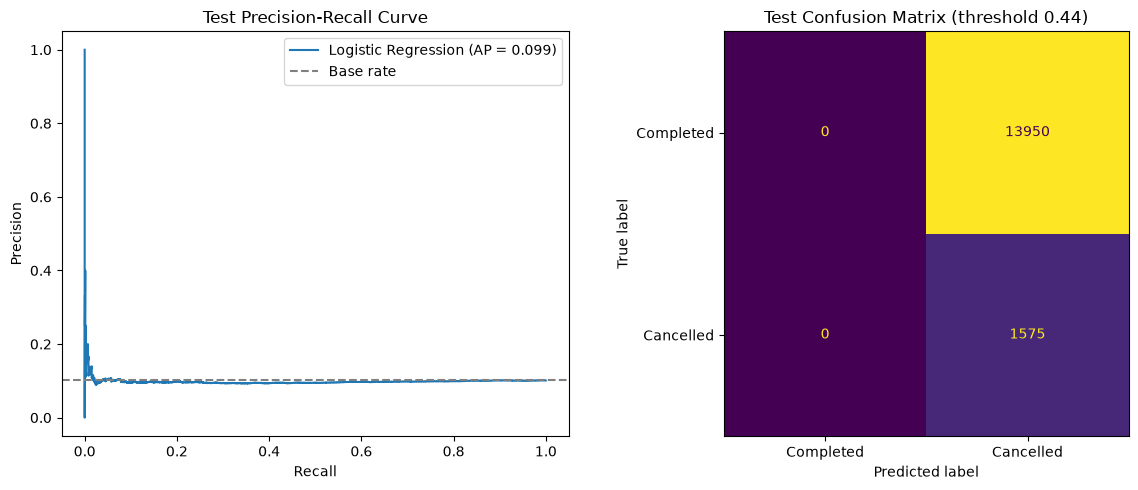

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Fit the final pipeline to all of the development data
final_pipeline.fit(X_dev, y_dev)

# Evaluate the model on the test set
test_probs = final_pipeline.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= threshold).astype(int)
test_ap = average_precision_score(y_test, test_probs)

print('Final test results for', final_name)
print(classification_report(y_test, test_pred, zero_division=0, target_names=['Completed', 'Cancelled']))
print(f'Test average precision: {test_ap:.4f}')
print(f'Base rate: {y_test.mean():.4f}')

# Plot the precision-recall curve and the confusion matrix
matplotlib.pyplot.figure(figsize=(12, 5))

matplotlib.pyplot.subplot(1, 2, 1)
test_precision, test_recall, _ = precision_recall_curve(y_test, test_probs)
matplotlib.pyplot.plot(test_recall, test_precision, label=f'{final_name} (AP = {test_ap:.3f})')
matplotlib.pyplot.axhline(y_test.mean(), color='gray', linestyle='--', label='Base rate')
matplotlib.pyplot.xlabel('Recall')
matplotlib.pyplot.ylabel('Precision')
matplotlib.pyplot.title('Test Precision-Recall Curve')
matplotlib.pyplot.legend()

ax2 = matplotlib.pyplot.subplot(1, 2, 2)
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=['Completed', 'Cancelled']).plot(ax=ax2, colorbar=False)
matplotlib.pyplot.title(f'Test Confusion Matrix (threshold {threshold:.2f})')

matplotlib.pyplot.tight_layout()
matplotlib.pyplot.show()

           feature  mean_importance  std_importance
1         Hour_cos          -0.0007          0.0007
5     Vehicle Type          -0.0006          0.0014
2        Month_sin          -0.0005          0.0009
6        DayOfWeek          -0.0004          0.0009
9            Route          -0.0002          0.0004
7  Pickup Location          -0.0000          0.0000
8    Drop Location           0.0000          0.0000
0         Hour_sin           0.0001          0.0002
3        Month_cos           0.0001          0.0003
4        IsWeekend           0.0005          0.0008


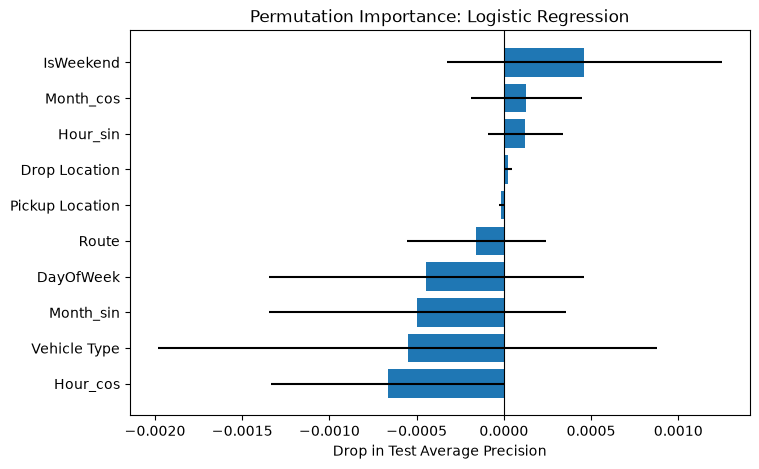

In [13]:
from sklearn.inspection import permutation_importance

# Measure how much the test average precision drops when each feature is shuffled
importance = permutation_importance(final_pipeline, X_test, y_test, scoring='average_precision', n_repeats=5, random_state=42, n_jobs=-1)

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'mean_importance': importance.importances_mean,
    'std_importance': importance.importances_std
}).sort_values('mean_importance')
print(importance_df.round(4))

# Plot the permutation importance of each feature
matplotlib.pyplot.figure(figsize=(8, 5))
matplotlib.pyplot.barh(importance_df['feature'], importance_df['mean_importance'], xerr=importance_df['std_importance'])
matplotlib.pyplot.axvline(0, color='black', linewidth=0.8)
matplotlib.pyplot.xlabel('Drop in Test Average Precision')
matplotlib.pyplot.title(f'Permutation Importance: {final_name}')
matplotlib.pyplot.show()

In [14]:
# Summarize the average precision at each stage of the project
summary = [
    {'stage': 'Baseline random forest (with VTAT)', 'data': 'validation', 'AP': average_precision_score(y_val, rf_vtat_probs)},
    {'stage': 'Baseline random forest (without VTAT)', 'data': 'validation',
     'AP': ablation_df[(ablation_df['model'] == 'Random Forest') & (ablation_df['features'] == 'without VTAT')]['validation_AP'].iloc[0]},
    {'stage': f'Tuned {final_name}', 'data': '5-fold CV', 'AP': results_df.set_index('model').loc[final_name, 'mean_validation_AP']},
    {'stage': f'Tuned {final_name}', 'data': 'test', 'AP': test_ap},
    {'stage': 'Dummy (base rate)', 'data': 'test', 'AP': y_test.mean()}
]

summary_df = pd.DataFrame(summary)
print(summary_df.round(4))

                                   stage        data      AP
0     Baseline random forest (with VTAT)  validation  0.4766
1  Baseline random forest (without VTAT)  validation  0.1024
2              Tuned Logistic Regression   5-fold CV  0.1026
3              Tuned Logistic Regression        test  0.0986
4                      Dummy (base rate)        test  0.1014
